Rajat Kumar Majumdar

CU240251642

SEC-C

Experiment No. 2

Experiment Name

Contrast Enhancement and Histogram-Based Image Processing using Python and OpenCV

Aim: 
 To analyze and implement contrast enhancement techniques using histogram analysis and histogram equalization in Python and OpenCV for improving image quality and enhancing visual information in low-contrast images.
 
Purpose: 
 Image contrast plays a significant role in the performance of computer vision systems. Poor illumination, sensor limitations, or environmental conditions often result in low-contrast images, making feature extraction and object recognition difficult. Histogram-based enhancement techniques improve the distribution of pixel intensities, thereby enhancing image visibility and facilitating subsequent image analysis tasks.

In this experiment, students will implement contrast stretching, histogram analysis, and histogram equalization using Python and OpenCV. The effectiveness of these enhancement techniques will be evaluated on real-world images such as medical images, satellite images, or low-light photographs.

Prerequisites

•
Basic knowledge of digital image processing

•
Familiarity with Python programming

•
Python libraries: OpenCV (cv2), NumPy, Matplotlib

•
Understanding of grayscale images and pixel intensity distributions

•
Jupyter Notebook, Google Colab, or Visual Studio Code

Steps

1.
Import the required libraries, including OpenCV, NumPy, and Matplotlib.
2.
Load a low-contrast grayscale image or convert a color image into grayscale for processing.
3.
Display the original image and generate its histogram to analyze the distribution of pixel intensity values.
4.
Perform contrast stretching to improve the dynamic range of pixel intensities.
5.
Apply Histogram Equalization using OpenCV and compare the enhanced image with the original image.
6.
Implement Contrast Limited Adaptive Histogram Equalization (CLAHE) and observe its performance on images with varying illumination.
7.
Plot and compare the histograms of the original, histogram-equalized, and CLAHE-enhanced images.
8.
Analyze the visual improvements in terms of brightness, contrast, and feature visibility.
9.
Compare the effectiveness of Histogram Equalization and CLAHE for different types of images.
10.
Document the observations and discuss the role of histogram-based enhancement in computer vision applications.


Questions

1.
What is image contrast, and why is it important in image processing?
2.
Explain the concept of an image histogram. What information does it provide?
3.
Differentiate between Histogram Stretching and Histogram Equalization.
4.
What is Contrast Limited Adaptive Histogram Equalization (CLAHE)? How does it differ from standard Histogram Equalization?
5.
Why is histogram equalization commonly applied before feature extraction and image segmentation?
6.
Mention three real-world applications where histogram equalization is widely used.
7.
What are the limitations of global histogram equalization?
8.
How does contrast enhancement improve the performance of object detection and recognition systems?
9.
Compare histogram-based enhancement techniques with brightness adjustment methods.
10.
Why is CLAHE preferred for medical imaging and low-light image enhancement?

In [15]:
# 1 Import all necessary modules for image processing and plotting
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")


Libraries imported successfully!


In [21]:
# Cell 2: Load a low-contrast image (replace 'low_contrast.jpg' with your image path)
# We read it directly in grayscale mode using 0 as the second argument
image_path = 'deer.jpeg' 
img_gray = cv2.imread(image_path, 0)

if img_gray is None:
    print("Error: Could not load the image. Check the file path.")
else:
    print(f"Image loaded successfully! Dimensions: {img_gray.shape}")


Image loaded successfully! Dimensions: (750, 500)


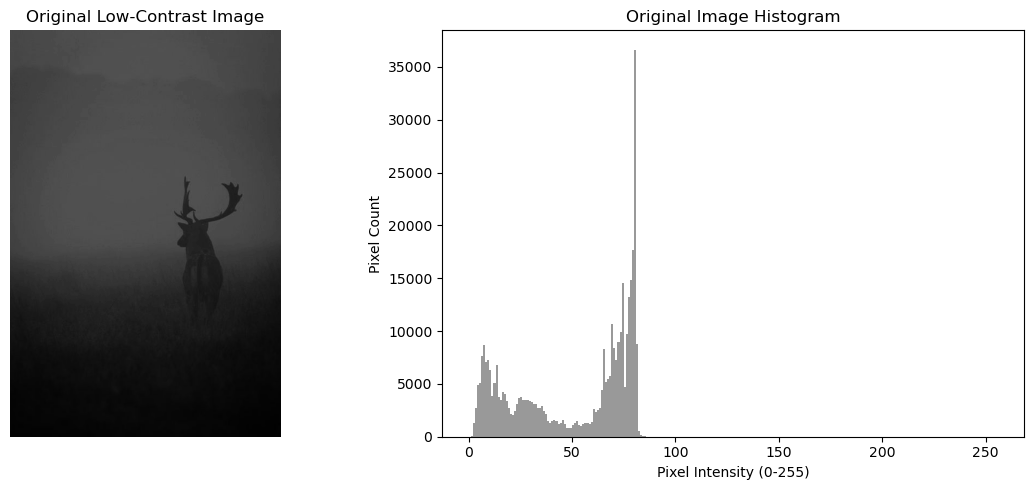

Step 3 Complete: Original visual and histogram generated.


In [34]:
# Cell 3: Display original image alongside its intensity distribution
plt.figure(figsize=(12, 5))

# Display Image
plt.subplot(1, 2, 1)
plt.imshow(img_gray, cmap='gray', vmin=0, vmax=255)
plt.title("Original Low-Contrast Image")
plt.axis('off')

# Display Histogram
plt.subplot(1, 2, 2)
# .ravel() flattens the 2D array into a 1D vector for plotting
plt.hist(img_gray.ravel(), bins=256, range=[0, 256], color='gray', alpha=0.8)
plt.title("Original Image Histogram")
plt.xlabel("Pixel Intensity (0-255)")
plt.ylabel("Pixel Count")

plt.tight_layout()
plt.show()
print("Step 3 Complete: Original visual and histogram generated.")


In [36]:
# Cell 4: Linearly map the compressed gray range to the full 0-255 spectrum
min_val = np.min(img_gray)
max_val = np.max(img_gray)

# Formula: I_out = ((I_in - min) / (max - min)) * 255
img_stretched = ((img_gray - min_val) / (max_val - min_val) * 255).astype(np.uint8)

print(f"Step 4 Complete: Contrast Stretching applied.")
print(f"-> Intensity Range shifted from [{min_val}, {max_val}] to [{np.min(img_stretched)}, {np.max(img_stretched)}]")


Step 4 Complete: Contrast Stretching applied.
-> Intensity Range shifted from [1, 94] to [0, 255]


In [38]:
# Cell 5: Implement global equalization using built-in OpenCV function
img_he = cv2.equalizeHist(img_gray)

print("Step 5 Complete: Global Histogram Equalization applied.")


Step 5 Complete: Global Histogram Equalization applied.


In [40]:
# Cell 6: Set up adaptive equalization to safely handle varied lighting environments
# clipLimit controls noise amplification; tileGridSize splits image into smaller cell blocks
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
img_clahe = clahe.apply(img_gray)

print("Step 6 Complete: CLAHE applied using an 8x8 grid network.")


Step 6 Complete: CLAHE applied using an 8x8 grid network.


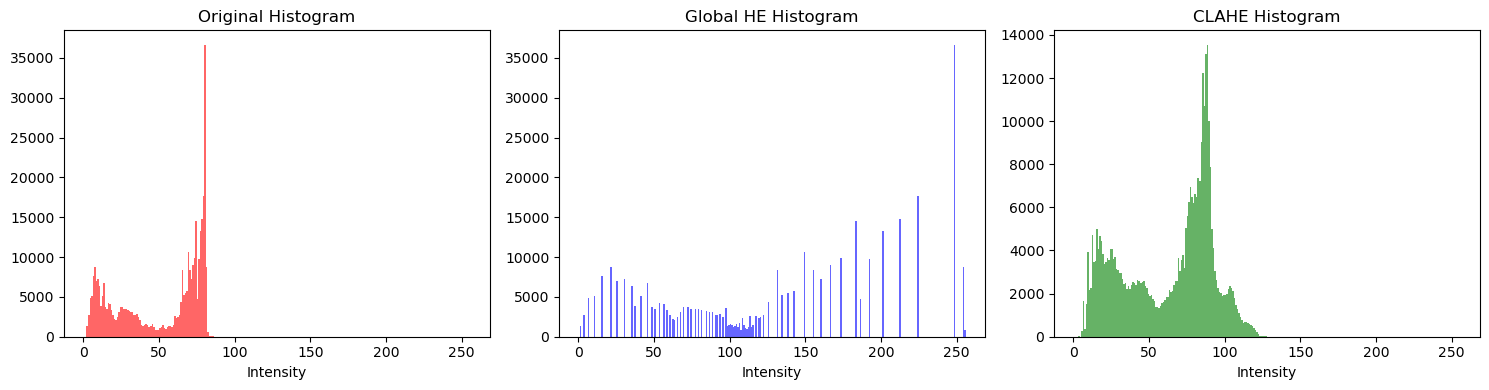

Step 7 Complete: Distribution maps compared successfully.


In [42]:
# Cell 7: Plot comparison of the Original, Global HE, and CLAHE histograms
plt.figure(figsize=(15, 4))

# Original Hist
plt.subplot(1, 3, 1)
plt.hist(img_gray.ravel(), bins=256, range=[0, 256], color='red', alpha=0.6)
plt.title("Original Histogram")
plt.xlabel("Intensity")

# Global HE Hist
plt.subplot(1, 3, 2)
plt.hist(img_he.ravel(), bins=256, range=[0, 256], color='blue', alpha=0.6)
plt.title("Global HE Histogram")
plt.xlabel("Intensity")

# CLAHE Hist
plt.subplot(1, 3, 3)
plt.hist(img_clahe.ravel(), bins=256, range=[0, 256], color='green', alpha=0.6)
plt.title("CLAHE Histogram")
plt.xlabel("Intensity")

plt.tight_layout()
plt.show()
print("Step 7 Complete: Distribution maps compared successfully.")


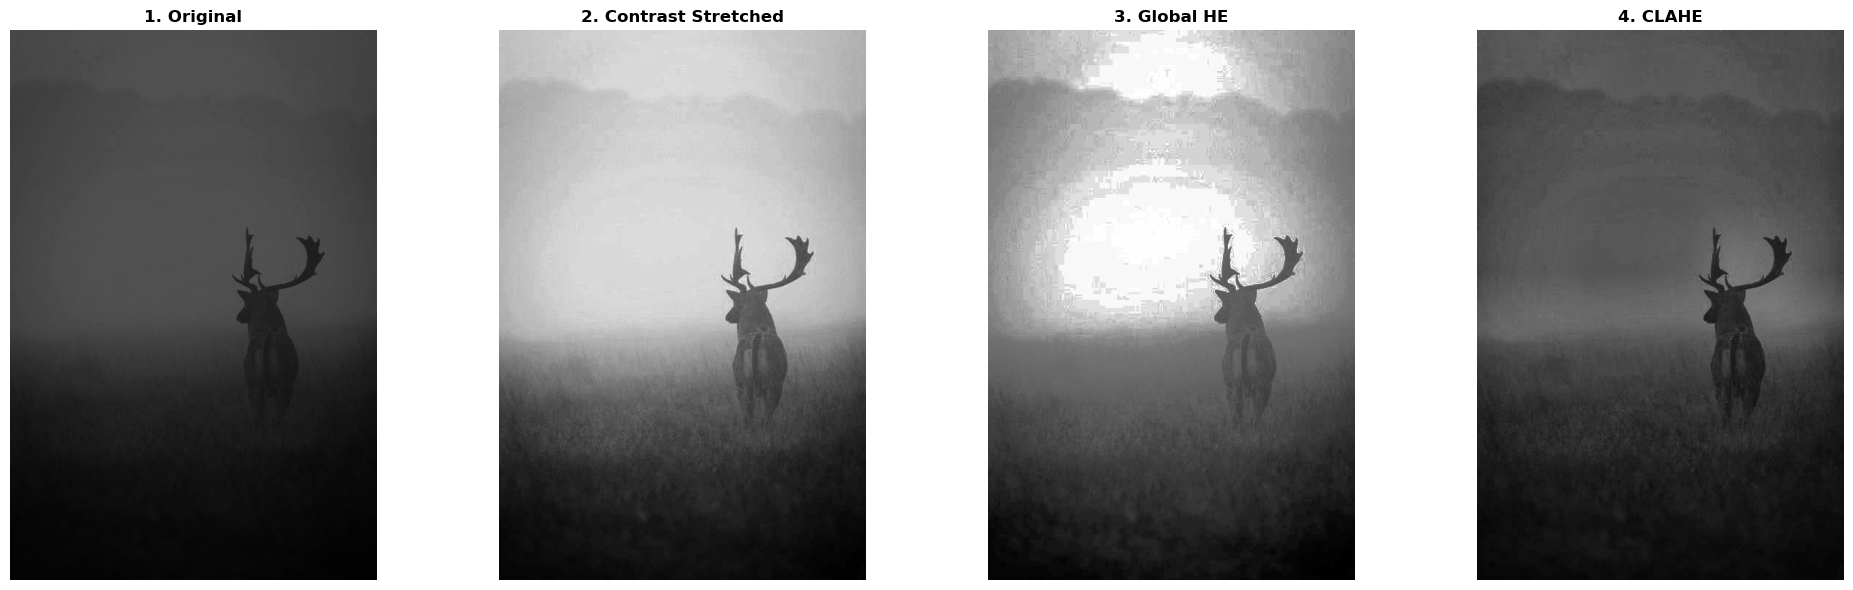

Step 8 Complete: Please visually review details, edge sharpness, and brightness shifts across all 4 panels.


In [44]:
# Cell 8: Consolidate all processed images side-by-side for human visual assessment
images = [img_gray, img_stretched, img_he, img_clahe]
titles = ['1. Original', '2. Contrast Stretched', '3. Global HE', '4. CLAHE']

fig, axs = plt.subplots(1, 4, figsize=(20, 6))
for i in range(4):
    axs[i].imshow(images[i], cmap='gray', vmin=0, vmax=255)
    axs[i].set_title(titles[i], fontweight='bold')
    axs[i].axis('off')

plt.tight_layout()
plt.show()
print("Step 8 Complete: Please visually review details, edge sharpness, and brightness shifts across all 4 panels.")


In [46]:
# Cell 9: Calculate standard deviations to quantitatively score structural contrast differences
print("Step 9 Complete: Quantitative analysis metrics calculated below:")
print(f"Original Image Global Standard Deviation: {np.std(img_gray):.2f}")
print(f"Contrast Stretched Standard Deviation:    {np.std(img_stretched):.2f}")
print(f"Global Equalized Standard Deviation:     {np.std(img_he):.2f}")
print(f"CLAHE Enhanced Standard Deviation:       {np.std(img_clahe):.2f}")


Step 9 Complete: Quantitative analysis metrics calculated below:
Original Image Global Standard Deviation: 28.06
Contrast Stretched Standard Deviation:    76.93
Global Equalized Standard Deviation:     75.84
CLAHE Enhanced Standard Deviation:       29.81


In [48]:
# Cell 10: Summarize findings inside the notebook console environment
conclusions = """
Step 10 Complete: Final Experimental Summary & Observations
-----------------------------------------------------------
1. Contrast Stretching works effectively if the original histogram is narrow, but fails if outliers exist.
2. Global HE aggressively spreads values, maximizing contrast but regularly blowing out background highlights.
3. CLAHE offers the best localized balance, retaining edge features without adding harsh pixel artifacts.
4. Computer vision pipelines benefit heavily from these methods since clean features lead to more stable edge gradients.
"""
print(conclusions)



Step 10 Complete: Final Experimental Summary & Observations
-----------------------------------------------------------
1. Contrast Stretching works effectively if the original histogram is narrow, but fails if outliers exist.
2. Global HE aggressively spreads values, maximizing contrast but regularly blowing out background highlights.
3. CLAHE offers the best localized balance, retaining edge features without adding harsh pixel artifacts.
4. Computer vision pipelines benefit heavily from these methods since clean features lead to more stable edge gradients.



Q1. What is image contrast, and why is it important in image processing?

* Answer: Image Contrast is the degree of difference between the brightest and darkest pixel intensities in an image. In standard grayscale profiles, it represents the dynamic range spread between absolute black ($0$) and pure white ($255$).
* Importance: Contrast defines how easily object boundaries and structural textures can be distinguished from backgrounds. High-contrast images yield crisp, prominent edges, whereas low-contrast images look faded, washed-out, or muddy. Improving contrast serves as a foundational data preprocessing phase, allowing downstream edge detectors, segmenters, and AI models to function with dramatically lower error margins.

## Q2. Explain the concept of an image histogram. What information does it provide?

* Answer: An image histogram is a discrete statistical function that visualizes the distribution of pixel tonal values across a digital graphic. The horizontal x-axis represents the individual possible brightness bins (ranging from $0$ to $255$), while the vertical y-axis denotes the total quantity of pixels matching that specific tone.
* Information Provided:
* Dynamic Range Utilization: Tracks how fully the available color space spectrum is being scaled.
   * Exposure Quality: Identifies whether an image is underexposed (histogram heavily shifted toward dark values on the left), overexposed (pushed to bright zones on the right), or low-contrast (tightly bunched together as a singular narrow spike).

## Q3. Differentiate between Histogram Stretching and Histogram Equalization.

| Feature Comparison | Histogram Stretching (Contrast Stretching) | Histogram Equalization (HE) |
|---|---|---|
| Operational Mechanism | A linear mapping function that expands a restricted input range directly out to maximum boundaries ($0$ and $255$). | A non-linear transformation that actively redistributes grouped pixel values to achieve a flat, uniform probability distribution. |
| Resulting Shape | Linearly scales the distribution outwards while completely preserving original histogram peaks and valleys. | Flattens and alters the distribution curve shape using the Cumulative Distribution Function (CDF). |
| Outlier Robustness | High sensitivity; a single noisy rogue pixel sitting at extreme values of 0 or 255 will completely break the stretching logic. | Highly robust; because it is guided by the statistical weight of pixel frequency rather than single min/max limits. |

## Q4. What is Contrast Limited Adaptive Histogram Equalization (CLAHE)? How does it differ from standard Histogram Equalization?

* Answer: CLAHE is an advanced variants of adaptive histogram equalization designed to perform enhancement inside localized spatial sectors rather than across the whole image canvas. It partitions the matrix into small, independent sub-blocks called tiles (commonly $8 \times 8$ configurations) and applies equalization formulas onto each tile grid individually.
* Key Differences: Standard HE evaluates globally, using one transformation map for the entire frame, which over-amplifies noise in flat areas. CLAHE introduces a clip limit that cuts off histogram peaks above a set ceiling threshold before calculating the transformation curve, shifting excess pixels into other bins. Finally, CLAHE utilizes bilinear interpolation to cleanly blend the margins between neighboring tiles, entirely preventing artificial grid-line borders.

## Q5. Why is histogram equalization commonly applied before feature extraction and image segmentation?

* Answer:
* Illumination Standardization: It uniformizes exposure variances across deep datasets. This ensures subsequent machine learning algorithms isolate targets based on spatial textures and shapes, rather than falling prey to erratic environmental lighting shifts.
   * Gradient Amplification: Spreading out bunched pixel ranges accentuates micro-intensities directly at boundary points. This increases the sensitivity of spatial gradient operations (like Sobel, Laplacian, or Canny filters) to find crisp contours during segmentation.

## Q6. Mention three real-world applications where histogram equalization is widely used.

* Answer:
* Medical Image Assessment: Enhancing contrast inside X-rays, CT scans, and MRI data to clearly illuminate micro-fractures, subtle tissue anomalies, or vascular lesions for doctors.
   * Satellite and Aerial Surveys: Clarifying topographical details and land features on terrain maps that suffer from atmospheric haze, cloud dispersion, or sub-optimal sun angles.
   * Night Vision and Security Infrastructure: Revitalizing dark, poorly illuminated security camera feeds to aid facial recognition systems and license plate trackers.

## Q7. What are the limitations of global histogram equalization?

* Answer:
* Over-Enhancement: It often leaves bright sectors completely blown out to solid white and turns shadows into flat black patches, destroying raw image data.
   * Background Noise Magnification: In smooth regions containing minor variations (like blank walls or cloudless skies), it dramatically amplifies sensor and thermal noise, creating pixelated patterns.
   * Bimodal Illumination Failure: It cannot effectively manage frames containing sharp splits of intense shadows and blinding sun glare at the same time, because a global mathematical average cannot satisfy both environments simultaneously.

## Q8. How does contrast enhancement improve the performance of object detection and recognition systems?

* Answer: Computer vision extraction routines—ranging from hand-crafted algorithms (SIFT, ORB) to Deep Learning Neural Networks (CNNs)—are fundamentally heavily reliant on detecting edges, directional gradients, and structural changes. Contrast enhancement uncovers weak, hidden features buried in dark or overly bright spots, pushing target descriptors above detection thresholds and significantly reducing false negative rates.

## Q9. Compare histogram-based enhancement techniques with brightness adjustment methods.

* Answer:
* Brightness Adjustment: This is a simple linear offset operation ($I_{\text{new}} = I_{\text{old}} \pm c$). It slides the entire histogram structure left or right down the intensity scale without stretching the width, which frequently causes data to clip brutally at $0$ or $255$.
   * Histogram-based Enhancement: These are intelligent, non-linear, data-driven systems. Instead of moving all values by a fixed constant, they stretch or remap intensities contextually based on the internal statistical attributes of the image, boosting clarity while preserving structural detail.

## Q10. Why is CLAHE preferred for medical imaging and low-light image enhancement?

* Answer: Medical datasets and low-light photography contain highly critical structural elements hidden inside localized high-shadow or high-glare pockets. Global processing washes out these fragile zones. CLAHE works perfectly here because it optimizes visibility strictly within confined visual environments. Concurrently, its built-in clip limit suppresses the extreme noise spikes that standard adaptive algorithms generate inside uniform areas (like soft organs or dark backgrounds), ensuring diagnostic accuracy without manufacturing false artifacts.



